# 06 - Classical Projection Baseline: CNN + 128D → 8D Projection + Metric Learning

## Objective

This notebook builds the **classical counterpart of the hybrid quantum model**.

Notebook 5 produced a 128-dimensional Siamese embedding. The quantum circuit
in the next notebooks can only accept a small number of inputs (8 qubits →
8 features), so the 128-D embedding has to be compressed to **8 dimensions**
first. This notebook asks:

> *How much verification performance survives when a classical network
> compresses the 128-D iris embedding into 8 dimensions?*

The answer is the **fair baseline** that the quantum model (Notebooks 7-8) must
beat. If the quantum circuit is placed on the same 8-D bottleneck, any
improvement can be attributed to the circuit and not to a different encoder,
different pairs or a different protocol.

## Architecture

```
Iris image (224 x 224)
      │
ResNet backbone + BN-neck   ← initialised from Notebook 5 (identity-disjoint, no leakage)
      │
128-D L2-normalised embedding
      │
Classical projection head   ← NEW: 128 → hidden → 8
      │
8-D L2-normalised embedding
      │
Contrastive loss on Siamese pairs
```

## Experimental Protocol

- Identity-disjoint train / validation / test splits from Notebook 3.
- **Same validation and test pairs as Notebook 5** (re-used from its saved
  CSV files), so results are directly comparable.
- Training pairs are re-sampled every epoch.
- Model selection and the verification threshold use validation data only.
- The test set is evaluated once, with the validation-selected threshold.
- The Notebook 5 encoder is safe to warm-start from: it was trained only on
  training identities (unlike Notebook 4, whose classifier may have seen
  validation/test identities).

## Outputs

1. Trained classical 128→8 projection model.
2. 8-D normalised iris embeddings (saved for all splits).
3. Verification accuracy, ROC / AUC, FAR, FRR, EER.
4. Validation-selected threshold.
5. Head-to-head comparison with the Notebook 5 128-D embedding.
6. Training curves and distance distributions.
7. Saved model, configuration and results for Notebooks 7-9.

In [1]:
# ============================================================
# CELL 2: Import libraries
# ============================================================

import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from PIL import Image

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    roc_curve,
    roc_auc_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import transforms

from torchvision.models import (
    resnet18, ResNet18_Weights,
    resnet34, ResNet34_Weights,
    resnet50, ResNet50_Weights,
)


print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# ============================================================
# CELL 3: Reproducibility
# ============================================================

SEED = 42


def set_seed(seed=SEED):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


set_seed()


print(f"Random seed set to: {SEED}")

Random seed set to: 42


In [3]:
# ============================================================
# CELL 4: Configuration
# ============================================================


# ------------------------------------------------------------
# Input directories
# ------------------------------------------------------------

DATA_SPLITS_ROOT = Path("../data_splits")          # Notebook 3

NB5_DIR = Path("../siamese_metric_learning")        # Notebook 5


# ------------------------------------------------------------
# Notebook 6 output directory
# ------------------------------------------------------------

OUTPUT_DIR = Path("../classical_projection_baseline")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Image configuration (must match Notebook 5)
# ------------------------------------------------------------

IMAGE_SIZE = 224


# ------------------------------------------------------------
# Encoder (must match Notebook 5 so its weights can be loaded)
# ------------------------------------------------------------

BACKBONE = "resnet34"          # "resnet18" | "resnet34" | "resnet50"

ENCODER_EMBEDDING_DIM = 128    # Notebook 5 embedding size

WARM_START_FROM_NB5 = True     # initialise encoder from Notebook 5

PRETRAINED_BACKBONE = True     # ImageNet weights when NOT warm-starting


# ------------------------------------------------------------
# Classical projection head: 128 -> hidden -> 8
# ------------------------------------------------------------
# PROJECTION_DIM = 8 is fixed by the number of qubits used later.
# PROJECTION_HIDDEN = 0 gives a purely linear 128 -> 8 projection.

PROJECTION_DIM = 8

PROJECTION_HIDDEN = 64

PROJECTION_DROPOUT = 0.1


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

BATCH_SIZE = 16                # PAIRS per batch = 32 images

NUM_EPOCHS = 40

ENCODER_LR = 3e-5              # warm-started encoder: very small LR

HEAD_LR = 1e-3                 # new projection head

WEIGHT_DECAY = 5e-4

PATIENCE = 12

FREEZE_ENCODER_EPOCHS = 3      # train only the new head first, so a
                               # randomly-initialised head cannot damage
                               # the good Notebook 5 encoder

NUM_WORKERS = 0                # Windows-safe


# ------------------------------------------------------------
# Metric learning configuration
# ------------------------------------------------------------

CONTRASTIVE_MARGIN = 1.0


# ------------------------------------------------------------
# Pair configuration
# ------------------------------------------------------------

TRAIN_PAIRS_PER_EPOCH = 6400

VALIDATION_PAIRS = 5000

TEST_PAIRS = 5000


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

USE_AMP = False                # fp16 gave NaN losses on GTX 16-series


print("Data splits directory:", DATA_SPLITS_ROOT)

print("Notebook 5 directory:", NB5_DIR)

print("Output directory:", OUTPUT_DIR)

print("Backbone:", BACKBONE)

print(f"Projection: {ENCODER_EMBEDDING_DIM} -> "
      f"{PROJECTION_HIDDEN if PROJECTION_HIDDEN else '(linear)'} -> "
      f"{PROJECTION_DIM}")

print("Device:", DEVICE)

print("Epochs:", NUM_EPOCHS)

print("Pairs per batch:", BATCH_SIZE)

Data splits directory: ..\data_splits
Notebook 5 directory: ..\siamese_metric_learning
Output directory: ..\classical_projection_baseline
Backbone: resnet34
Projection: 128 -> 64 -> 8
Device: cuda
Epochs: 40
Pairs per batch: 16


In [4]:
# ============================================================
# CELL 5: Verify input directories and Notebook 5 artefacts
# ============================================================

if not DATA_SPLITS_ROOT.exists():

    raise FileNotFoundError(
        f"Notebook 3 output directory was not found:\n"
        f"{DATA_SPLITS_ROOT}"
    )


NB5_MODEL_PATH = NB5_DIR / "best_siamese_metric_model.pth"

NB5_VAL_PAIRS = NB5_DIR / "validation_pairs.csv"

NB5_TEST_PAIRS = NB5_DIR / "test_pairs.csv"

NB5_RESULTS = NB5_DIR / "final_results.csv"


for name, path in [
    ("Notebook 5 model", NB5_MODEL_PATH),
    ("Notebook 5 validation pairs", NB5_VAL_PAIRS),
    ("Notebook 5 test pairs", NB5_TEST_PAIRS),
    ("Notebook 5 results", NB5_RESULTS),
]:

    print(f"{name:32s}", "FOUND" if path.exists() else "missing", "-", path)


if WARM_START_FROM_NB5 and not NB5_MODEL_PATH.exists():

    raise FileNotFoundError(
        "WARM_START_FROM_NB5 is True but the Notebook 5 checkpoint "
        "was not found. Run Notebook 5 first or set "
        "WARM_START_FROM_NB5 = False."
    )

Notebook 5 model                 FOUND - ..\siamese_metric_learning\best_siamese_metric_model.pth
Notebook 5 validation pairs      FOUND - ..\siamese_metric_learning\validation_pairs.csv
Notebook 5 test pairs            FOUND - ..\siamese_metric_learning\test_pairs.csv
Notebook 5 results               FOUND - ..\siamese_metric_learning\final_results.csv


In [5]:
# ============================================================
# CELL 6: Load Notebook 3 data splits
# ============================================================

def find_csv(possible_names):

    for name in possible_names:

        path = DATA_SPLITS_ROOT / name

        if path.exists():

            return path

    raise FileNotFoundError(f"None of {possible_names} found.")


TRAIN_CSV = find_csv(["train.csv", "training.csv"])

VALIDATION_CSV = find_csv(["validation.csv", "val.csv"])

TEST_CSV = find_csv(["test.csv"])


train_df = pd.read_csv(TRAIN_CSV)

validation_df = pd.read_csv(VALIDATION_CSV)

test_df = pd.read_csv(TEST_CSV)


print("=" * 60)

print("DATASET SPLITS")

print("=" * 60)

print("\nTrain shape:", train_df.shape)

print("Validation shape:", validation_df.shape)

print("Test shape:", test_df.shape)

print("\nAvailable columns:")

print(train_df.columns.tolist())


# ------------------------------------------------------------
# Detect identity and path columns
# ------------------------------------------------------------

IDENTITY_CANDIDATES = [
    "identity", "eye_id", "subject_id", "class_id", "label"
]

PATH_CANDIDATES = [
    "processed_path", "image_path", "path", "filepath", "file_path"
]


def find_column(dataframe, candidates):

    for column in candidates:

        if column in dataframe.columns:

            return column

    return None


IDENTITY_COLUMN = find_column(train_df, IDENTITY_CANDIDATES)

PATH_COLUMN = find_column(train_df, PATH_CANDIDATES)


if IDENTITY_COLUMN is None or PATH_COLUMN is None:

    raise ValueError(
        f"Could not detect columns. Available: {train_df.columns.tolist()}"
    )


print("\nIdentity column detected:", IDENTITY_COLUMN)

print("Image path column detected:", PATH_COLUMN)

DATASET SPLITS

Train shape: (14000, 6)
Validation shape: (3000, 6)
Test shape: (3000, 6)

Available columns:
['subject_id', 'eye', 'identity', 'image_index', 'image_name', 'processed_path']

Identity column detected: identity
Image path column detected: processed_path


In [6]:
# ============================================================
# CELL 7: Resolve and verify image paths
# ============================================================

def resolve_image_path(path_value):

    path = Path(str(path_value))

    if path.exists():

        return str(path.resolve())

    candidate = DATA_SPLITS_ROOT / path

    if candidate.exists():

        return str(candidate.resolve())

    candidate = Path.cwd() / path

    if candidate.exists():

        return str(candidate.resolve())

    return str(path)


for dataframe in [train_df, validation_df, test_df]:

    dataframe[PATH_COLUMN] = dataframe[PATH_COLUMN].apply(
        resolve_image_path
    )


def verify_paths(dataframe, split_name):

    missing = dataframe.loc[
        ~dataframe[PATH_COLUMN].apply(lambda p: Path(p).exists())
    ]

    print(f"{split_name} missing images:", len(missing))

    if len(missing) > 0:

        display(missing[[IDENTITY_COLUMN, PATH_COLUMN]].head())

        raise FileNotFoundError(
            f"{split_name} contains missing image files."
        )


verify_paths(train_df, "Training")

verify_paths(validation_df, "Validation")

verify_paths(test_df, "Test")

print("\n✓ All image files were found successfully.")

Training missing images: 0
Validation missing images: 0
Test missing images: 0

✓ All image files were found successfully.


In [7]:
# ============================================================
# CELL 8: Verify identity-disjoint protocol
# ============================================================

train_ids = set(train_df[IDENTITY_COLUMN].unique())

validation_ids = set(validation_df[IDENTITY_COLUMN].unique())

test_ids = set(test_df[IDENTITY_COLUMN].unique())


print("=" * 60)

print("IDENTITY-DISJOINT SPLIT VERIFICATION")

print("=" * 60)

print("\nTrain identities:", len(train_ids))

print("Validation identities:", len(validation_ids))

print("Test identities:", len(test_ids))

print("\nTrain ∩ Validation:", len(train_ids & validation_ids))

print("Train ∩ Test:", len(train_ids & test_ids))

print("Validation ∩ Test:", len(validation_ids & test_ids))


assert len(train_ids & validation_ids) == 0

assert len(train_ids & test_ids) == 0

assert len(validation_ids & test_ids) == 0


print("\n✓ All splits are identity-disjoint.")

IDENTITY-DISJOINT SPLIT VERIFICATION

Train identities: 1400
Validation identities: 300
Test identities: 300

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

✓ All splits are identity-disjoint.


In [8]:
# ============================================================
# CELL 9: Image transformations (identical to Notebook 5)
# ============================================================
#
# No horizontal flip: each image of a pair is transformed independently,
# and a flipped left iris resembles a right iris.


NORMALIZE_MEAN = [0.485, 0.456, 0.406]

NORMALIZE_STD = [0.229, 0.224, 0.225]


train_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

        transforms.RandomApply(
            [
                transforms.RandomAffine(
                    degrees=10,
                    translate=(0.06, 0.06),
                    scale=(0.90, 1.10),
                    shear=4,
                    fill=0
                )
            ],
            p=0.8
        ),

        transforms.ColorJitter(
            brightness=0.30,
            contrast=0.30
        ),

        transforms.RandomApply(
            [
                transforms.GaussianBlur(
                    kernel_size=3,
                    sigma=(0.1, 1.2)
                )
            ],
            p=0.25
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=NORMALIZE_MEAN,
            std=NORMALIZE_STD
        ),

        transforms.RandomErasing(
            p=0.30,
            scale=(0.02, 0.12),
            ratio=(0.3, 3.3),
            value=0
        )
    ]
)


evaluation_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=NORMALIZE_MEAN,
            std=NORMALIZE_STD
        )
    ]
)


print("Image transformations configured.")

Image transformations configured.


In [9]:
# ============================================================
# CELL 10: Pair datasets
# ============================================================
#
# SiamesePairDataset : random pairs, re-sampled every epoch (training)
# FixedPairDataset   : pairs read from a CSV (validation / test),
#                      so Notebook 5 and Notebook 6 are evaluated on
#                      EXACTLY the same pairs.
#
# Label convention (same as Notebook 5):
#   0 = same identity (genuine)
#   1 = different identity (impostor)


class SiamesePairDataset(Dataset):

    def __init__(
        self,
        dataframe,
        identity_column,
        path_column,
        num_pairs,
        transform=None,
        seed=42
    ):

        self.dataframe = dataframe.reset_index(drop=True).copy()

        self.identity_column = identity_column

        self.path_column = path_column

        self.num_pairs = num_pairs

        self.transform = transform

        self.seed = seed

        self.identity_to_indices = {
            identity: group.index.tolist()
            for identity, group in self.dataframe.groupby(identity_column)
        }

        self.identities = list(self.identity_to_indices.keys())

        self.valid_positive_ids = [
            identity
            for identity, indices in self.identity_to_indices.items()
            if len(indices) >= 2
        ]

        if len(self.valid_positive_ids) == 0:

            raise ValueError(
                "No identity has at least two images."
            )

        self.create_pairs()

    def create_pairs(self):

        rng = random.Random(self.seed)

        self.pairs = []

        num_positive = self.num_pairs // 2

        num_negative = self.num_pairs - num_positive

        for _ in range(num_positive):

            identity = rng.choice(self.valid_positive_ids)

            index1, index2 = rng.sample(
                self.identity_to_indices[identity], 2
            )

            self.pairs.append((index1, index2, 0.0))

        for _ in range(num_negative):

            identity1, identity2 = rng.sample(self.identities, 2)

            index1 = rng.choice(self.identity_to_indices[identity1])

            index2 = rng.choice(self.identity_to_indices[identity2])

            self.pairs.append((index1, index2, 1.0))

        rng.shuffle(self.pairs)

    def regenerate_pairs(self, epoch):

        self.seed = SEED + epoch

        self.create_pairs()

    def to_dataframe(self):

        return pd.DataFrame(
            [
                {
                    "image1_path":
                        self.dataframe.iloc[i1][self.path_column],
                    "image2_path":
                        self.dataframe.iloc[i2][self.path_column],
                    "label":
                        int(label)
                }
                for i1, i2, label in self.pairs
            ]
        )

    def __len__(self):

        return len(self.pairs)

    def __getitem__(self, index):

        index1, index2, label = self.pairs[index]

        image1 = Image.open(
            self.dataframe.iloc[index1][self.path_column]
        ).convert("RGB")

        image2 = Image.open(
            self.dataframe.iloc[index2][self.path_column]
        ).convert("RGB")

        if self.transform is not None:

            image1 = self.transform(image1)

            image2 = self.transform(image2)

        return image1, image2, torch.tensor(label, dtype=torch.float32)


class FixedPairDataset(Dataset):

    def __init__(self, pairs_dataframe, transform=None):

        self.pairs_dataframe = pairs_dataframe.reset_index(drop=True)

        self.transform = transform

    def __len__(self):

        return len(self.pairs_dataframe)

    def __getitem__(self, index):

        row = self.pairs_dataframe.iloc[index]

        image1 = Image.open(row["image1_path"]).convert("RGB")

        image2 = Image.open(row["image2_path"]).convert("RGB")

        if self.transform is not None:

            image1 = self.transform(image1)

            image2 = self.transform(image2)

        return (
            image1,
            image2,
            torch.tensor(float(row["label"]), dtype=torch.float32)
        )


print("Pair dataset classes defined.")

Pair dataset classes defined.


In [10]:
# ============================================================
# CELL 11: Create pair datasets (re-use Notebook 5 eval pairs)
# ============================================================

train_pair_dataset = SiamesePairDataset(
    dataframe=train_df,
    identity_column=IDENTITY_COLUMN,
    path_column=PATH_COLUMN,
    num_pairs=TRAIN_PAIRS_PER_EPOCH,
    transform=train_transform,
    seed=SEED
)


def load_or_create_eval_pairs(
    nb5_pairs_path,
    split_dataframe,
    num_pairs,
    seed,
    split_name
):

    # Re-use Notebook 5 pairs if they exist, are readable on this
    # machine, and only contain images from this split.

    if nb5_pairs_path.exists():

        pairs_df = pd.read_csv(nb5_pairs_path)

        split_paths = set(split_dataframe[PATH_COLUMN])

        paths_ok = (
            all(Path(p).exists() for p in pairs_df["image1_path"])
            and all(Path(p).exists() for p in pairs_df["image2_path"])
        )

        in_split = (
            set(pairs_df["image1_path"]) <= split_paths
            and set(pairs_df["image2_path"]) <= split_paths
        )

        if paths_ok and in_split:

            print(f"{split_name}: re-using {len(pairs_df)} pairs "
                  f"from Notebook 5.")

            return pairs_df, True

        print(f"{split_name}: Notebook 5 pairs unusable "
              f"(paths_ok={paths_ok}, in_split={in_split}).")

    print(f"{split_name}: generating {num_pairs} new pairs.")

    generated = SiamesePairDataset(
        dataframe=split_dataframe,
        identity_column=IDENTITY_COLUMN,
        path_column=PATH_COLUMN,
        num_pairs=num_pairs,
        transform=None,
        seed=seed
    )

    return generated.to_dataframe(), False


validation_pairs_df, val_pairs_shared = load_or_create_eval_pairs(
    NB5_VAL_PAIRS, validation_df, VALIDATION_PAIRS, SEED, "Validation"
)

test_pairs_df, test_pairs_shared = load_or_create_eval_pairs(
    NB5_TEST_PAIRS, test_df, TEST_PAIRS, SEED + 1, "Test"
)

SAME_PAIRS_AS_NB5 = val_pairs_shared and test_pairs_shared


validation_pairs_df.to_csv(OUTPUT_DIR / "validation_pairs.csv", index=False)

test_pairs_df.to_csv(OUTPUT_DIR / "test_pairs.csv", index=False)


validation_pair_dataset = FixedPairDataset(
    validation_pairs_df, evaluation_transform
)

test_pair_dataset = FixedPairDataset(
    test_pairs_df, evaluation_transform
)


print("\nTraining pairs per epoch:", len(train_pair_dataset))

print("Validation pairs:", len(validation_pair_dataset))

print("Test pairs:", len(test_pair_dataset))

print("\nIdentical evaluation pairs to Notebook 5:", SAME_PAIRS_AS_NB5)

Validation: re-using 5000 pairs from Notebook 5.
Test: re-using 5000 pairs from Notebook 5.

Training pairs per epoch: 6400
Validation pairs: 5000
Test pairs: 5000

Identical evaluation pairs to Notebook 5: True


In [11]:
# ============================================================
# CELL 12: Create DataLoaders
# ============================================================

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda"
}

if NUM_WORKERS > 0:

    loader_kwargs["persistent_workers"] = True


train_loader = DataLoader(
    train_pair_dataset,
    shuffle=True,
    drop_last=True,         # BatchNorm needs more than 1 sample
    **loader_kwargs
)

validation_loader = DataLoader(
    validation_pair_dataset,
    shuffle=False,
    **loader_kwargs
)

test_loader = DataLoader(
    test_pair_dataset,
    shuffle=False,
    **loader_kwargs
)


print("DataLoaders created successfully.")

DataLoaders created successfully.


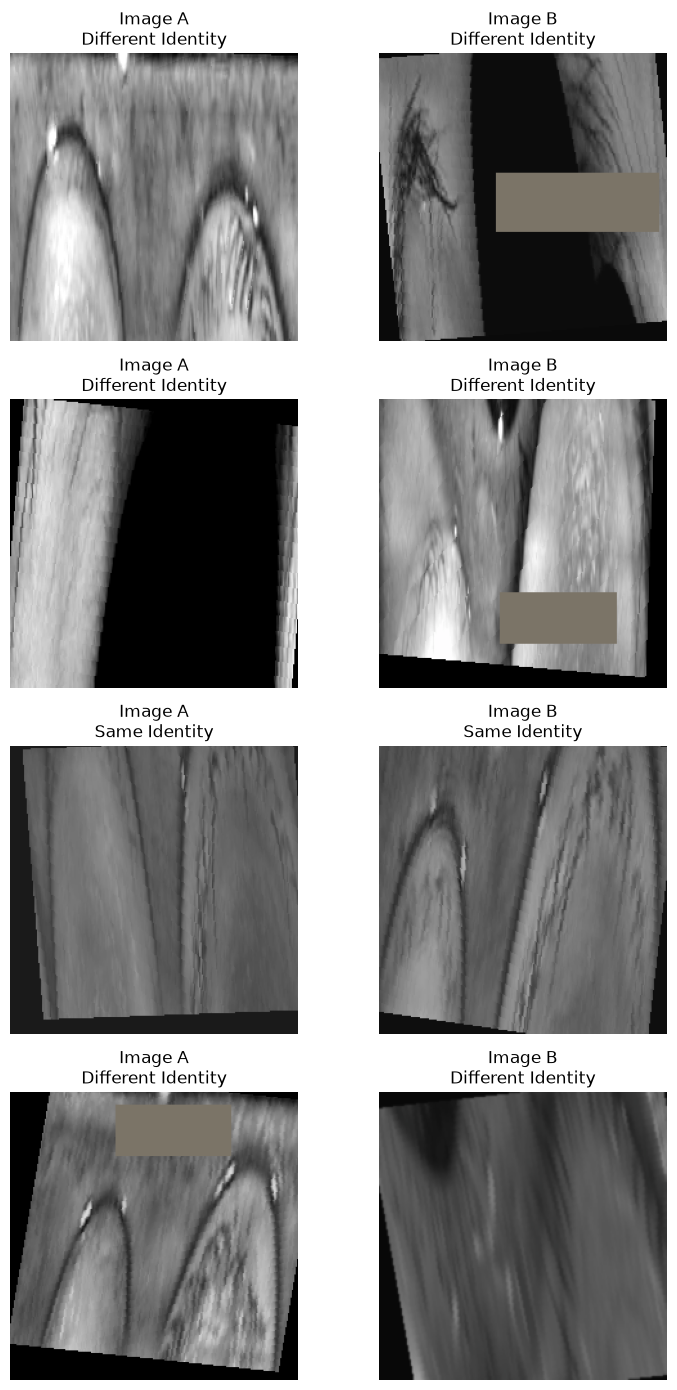

In [12]:
# ============================================================
# CELL 13: Visualize sample pairs
# ============================================================

def denormalize_image(image_tensor):

    image = image_tensor.clone()

    mean = torch.tensor(NORMALIZE_MEAN).view(3, 1, 1)

    std = torch.tensor(NORMALIZE_STD).view(3, 1, 1)

    return torch.clamp(image * std + mean, 0, 1)


image1_batch, image2_batch, label_batch = next(iter(train_loader))

rows = min(4, len(label_batch))

fig, axes = plt.subplots(rows, 2, figsize=(8, 3.5 * rows))

axes = np.atleast_2d(axes)

for row in range(rows):

    pair_type = (
        "Same Identity"
        if label_batch[row].item() == 0
        else "Different Identity"
    )

    axes[row, 0].imshow(
        denormalize_image(image1_batch[row]).permute(1, 2, 0).numpy()
    )

    axes[row, 1].imshow(
        denormalize_image(image2_batch[row]).permute(1, 2, 0).numpy()
    )

    axes[row, 0].set_title(f"Image A\n{pair_type}")

    axes[row, 1].set_title(f"Image B\n{pair_type}")

    axes[row, 0].axis("off")

    axes[row, 1].axis("off")

plt.tight_layout()

plt.show()

In [13]:
# ============================================================
# CELL 14: Encoder (same architecture as Notebook 5)
# ============================================================

def build_backbone(name, pretrained=True):

    if name == "resnet18":

        trunk = resnet18(
            weights=ResNet18_Weights.DEFAULT if pretrained else None
        )

    elif name == "resnet34":

        trunk = resnet34(
            weights=ResNet34_Weights.DEFAULT if pretrained else None
        )

    elif name == "resnet50":

        trunk = resnet50(
            weights=ResNet50_Weights.DEFAULT if pretrained else None
        )

    else:

        raise ValueError(f"Unknown backbone: {name}")

    num_features = trunk.fc.in_features

    trunk.fc = nn.Identity()

    return trunk, num_features


class SiameseEncoder(nn.Module):

    # Parameter names are identical to Notebook 5
    # (backbone.* and embedding_layer.*) so its checkpoint loads directly.

    def __init__(
        self,
        embedding_dim=128,
        backbone_name=None,
        dropout=0.2,
        pretrained=True
    ):

        super().__init__()

        backbone_name = backbone_name or BACKBONE

        self.backbone, num_features = build_backbone(
            backbone_name, pretrained=pretrained
        )

        self.embedding_layer = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(num_features, embedding_dim, bias=False),
            nn.BatchNorm1d(embedding_dim)
        )

    def forward(self, x):

        features = self.backbone(x)

        embedding = self.embedding_layer(features)

        return F.normalize(embedding, p=2, dim=1)

In [14]:
# ============================================================
# CELL 15: Classical projection head (128 -> 8) and full model
# ============================================================
#
# The head is deliberately small: the 8-D output is the bottleneck that
# the quantum circuit will sit on in Notebooks 7-8. In those notebooks
# this head is replaced / followed by the quantum layer.
#
#   PROJECTION_HIDDEN > 0 : Linear -> BN -> GELU -> Dropout -> Linear -> BN
#   PROJECTION_HIDDEN = 0 : Linear -> BN          (purely linear)


class ProjectionHead(nn.Module):

    def __init__(
        self,
        in_dim=128,
        out_dim=8,
        hidden_dim=64,
        dropout=0.1
    ):

        super().__init__()

        if hidden_dim and hidden_dim > 0:

            self.net = nn.Sequential(
                nn.Linear(in_dim, hidden_dim, bias=False),
                nn.BatchNorm1d(hidden_dim),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(hidden_dim, out_dim, bias=False),
                nn.BatchNorm1d(out_dim)
            )

        else:

            self.net = nn.Sequential(
                nn.Linear(in_dim, out_dim, bias=False),
                nn.BatchNorm1d(out_dim)
            )

    def forward(self, x):

        return F.normalize(self.net(x), p=2, dim=1)


class ClassicalProjectionSiamese(nn.Module):

    def __init__(
        self,
        encoder_dim=128,
        projection_dim=8,
        hidden_dim=64,
        dropout=0.1,
        pretrained_backbone=True
    ):

        super().__init__()

        self.encoder = SiameseEncoder(
            embedding_dim=encoder_dim,
            pretrained=pretrained_backbone
        )

        self.projection = ProjectionHead(
            in_dim=encoder_dim,
            out_dim=projection_dim,
            hidden_dim=hidden_dim,
            dropout=dropout
        )

    def embed(self, x):

        # 8-D embedding of a single image batch

        return self.projection(self.encoder(x))

    def embed_both(self, x):

        # Returns (128-D, 8-D)

        e128 = self.encoder(x)

        return e128, self.projection(e128)

    def forward(self, image1, image2):

        return self.embed(image1), self.embed(image2)

In [15]:
# ============================================================
# CELL 16: Build model and warm-start encoder from Notebook 5
# ============================================================

model = ClassicalProjectionSiamese(
    encoder_dim=ENCODER_EMBEDDING_DIM,
    projection_dim=PROJECTION_DIM,
    hidden_dim=PROJECTION_HIDDEN,
    dropout=PROJECTION_DROPOUT,
    pretrained_backbone=PRETRAINED_BACKBONE and not WARM_START_FROM_NB5
).to(DEVICE)


if WARM_START_FROM_NB5:

    nb5_checkpoint = torch.load(
        NB5_MODEL_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    # Notebook 5 keys look like "encoder.backbone.conv1.weight"
    # -> strip the leading "encoder." to load into model.encoder

    nb5_state = {
        key[len("encoder."):]: value
        for key, value in nb5_checkpoint["model_state_dict"].items()
        if key.startswith("encoder.")
    }

    model.encoder.load_state_dict(nb5_state, strict=True)

    print("✓ Encoder weights loaded from Notebook 5.")

    print("  Notebook 5 best epoch:", nb5_checkpoint["epoch"])

    print("  Notebook 5 validation AUC:",
          round(float(nb5_checkpoint["validation_auc"]), 4))

else:

    print("Encoder initialised from",
          "ImageNet weights." if PRETRAINED_BACKBONE else "scratch.")


total_parameters = sum(p.numel() for p in model.parameters())

projection_parameters = sum(p.numel() for p in model.projection.parameters())

print("\nTotal parameters:", total_parameters)

print("Projection head parameters:", projection_parameters)

print("\nProjection head:\n")

print(model.projection)

✓ Encoder weights loaded from Notebook 5.
  Notebook 5 best epoch: 60
  Notebook 5 validation AUC: 0.8831

Total parameters: 21359312
Projection head parameters: 8848

Projection head:

ProjectionHead(
  (net): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=False)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=64, out_features=8, bias=False)
    (5): BatchNorm1d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
)


In [16]:
# ============================================================
# CELL 17: Contrastive loss, optimizer, scheduler
# ============================================================

class ContrastiveLoss(nn.Module):

    def __init__(self, margin=1.0):

        super().__init__()

        self.margin = margin

    def forward(self, embedding1, embedding2, labels):

        distances = F.pairwise_distance(embedding1, embedding2)

        # label 0 (genuine)  : pull together
        # label 1 (impostor) : push beyond margin

        genuine_loss = (1 - labels) * distances.pow(2)

        impostor_loss = labels * torch.clamp(
            self.margin - distances, min=0.0
        ).pow(2)

        return (genuine_loss + impostor_loss).mean(), distances


criterion = ContrastiveLoss(margin=CONTRASTIVE_MARGIN)


def build_param_groups(module, lr, weight_decay):

    decay, no_decay = [], []

    for name, parameter in module.named_parameters():

        if parameter.ndim <= 1 or name.endswith(".bias"):

            no_decay.append(parameter)

        else:

            decay.append(parameter)

    return [
        {"params": decay, "lr": lr, "weight_decay": weight_decay},
        {"params": no_decay, "lr": lr, "weight_decay": 0.0},
    ]


optimizer = optim.AdamW(
    build_param_groups(model.encoder, ENCODER_LR, WEIGHT_DECAY)
    + build_param_groups(model.projection, HEAD_LR, WEIGHT_DECAY)
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)


# ------------------------------------------------------------
# Save the recipe so later notebooks can rebuild the model
# ------------------------------------------------------------

MODEL_CONFIG = {
    "backbone": BACKBONE,
    "encoder_embedding_dim": ENCODER_EMBEDDING_DIM,
    "projection_dim": PROJECTION_DIM,
    "projection_hidden": PROJECTION_HIDDEN,
    "projection_dropout": PROJECTION_DROPOUT,
    "image_size": IMAGE_SIZE,
    "normalize_mean": NORMALIZE_MEAN,
    "normalize_std": NORMALIZE_STD,
}

with open(OUTPUT_DIR / "model_config.json", "w") as file:

    json.dump(MODEL_CONFIG, file, indent=2)


print("Loss, optimizer and scheduler ready.")

print("Model config saved to:", OUTPUT_DIR / "model_config.json")

Loss, optimizer and scheduler ready.
Model config saved to: ..\classical_projection_baseline\model_config.json


In [17]:
# ============================================================
# CELL 18: Distance prediction, train / evaluate functions
# ============================================================

def predict_from_distance(distances, threshold):

    # distance <= threshold  ->  SAME identity  ->  label 0

    return (distances > threshold).astype(int)


def set_encoder_frozen(model, frozen):

    for parameter in model.encoder.parameters():

        parameter.requires_grad = not frozen


def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    encoder_frozen=False
):

    model.train()

    if encoder_frozen:

        # Also freeze BatchNorm statistics / dropout of the encoder

        model.encoder.eval()

    running_loss = 0.0

    seen = 0

    for image1, image2, labels in tqdm(
        dataloader, desc="Training", leave=False
    ):

        image1 = image1.to(DEVICE, non_blocking=True)

        image2 = image2.to(DEVICE, non_blocking=True)

        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad()

        embedding1, embedding2 = model(image1, image2)

        loss, _ = criterion(embedding1, embedding2, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            [p for p in model.parameters() if p.requires_grad],
            max_norm=5.0
        )

        optimizer.step()

        running_loss += loss.item() * image1.size(0)

        seen += image1.size(0)

    return running_loss / max(seen, 1)


def evaluate_model(model, dataloader, criterion):

    model.eval()

    running_loss = 0.0

    all_distances = []

    all_labels = []

    with torch.no_grad():

        for image1, image2, labels in tqdm(
            dataloader, desc="Evaluating", leave=False
        ):

            image1 = image1.to(DEVICE, non_blocking=True)

            image2 = image2.to(DEVICE, non_blocking=True)

            labels = labels.to(DEVICE, non_blocking=True)

            embedding1, embedding2 = model(image1, image2)

            loss, distances = criterion(embedding1, embedding2, labels)

            running_loss += loss.item() * image1.size(0)

            all_distances.extend(distances.cpu().numpy())

            all_labels.extend(labels.cpu().numpy())

    return (
        running_loss / len(dataloader.dataset),
        np.array(all_distances),
        np.array(all_labels)
    )

In [18]:
# ============================================================
# CELL 19: Verification metrics
# ============================================================

def calculate_far_frr(distances, labels, threshold):

    predictions = predict_from_distance(distances, threshold)

    genuine_mask = labels == 0

    impostor_mask = labels == 1

    false_rejections = np.sum(predictions[genuine_mask] == 1)

    false_accepts = np.sum(predictions[impostor_mask] == 0)

    genuine_count = np.sum(genuine_mask)

    impostor_count = np.sum(impostor_mask)

    FRR = false_rejections / genuine_count if genuine_count > 0 else 0.0

    FAR = false_accepts / impostor_count if impostor_count > 0 else 0.0

    return FAR, FRR


def get_validation_metrics(distances, labels):

    # 1 = genuine / same, 0 = impostor / different.
    # Smaller distance = more genuine, so -distance is the score.

    genuine_labels = 1 - labels

    scores = -distances

    fpr, tpr, roc_thresholds = roc_curve(genuine_labels, scores)

    auc_score = roc_auc_score(genuine_labels, scores)

    # Youden's J statistic

    best_index = np.argmax(tpr - fpr)

    best_distance_threshold = -roc_thresholds[best_index]

    predictions = predict_from_distance(distances, best_distance_threshold)

    accuracy = accuracy_score(labels, predictions)

    # EER approximation from ROC points

    fnr = 1 - tpr

    eer_index = np.argmin(np.abs(fpr - fnr))

    eer = (fpr[eer_index] + fnr[eer_index]) / 2

    eer_distance_threshold = -roc_thresholds[eer_index]

    return {
        "accuracy": accuracy,
        "auc": auc_score,
        "threshold": best_distance_threshold,
        "eer": eer,
        "eer_threshold": eer_distance_threshold,
        "fpr": fpr,
        "tpr": tpr,
        "roc_thresholds": roc_thresholds
    }

In [19]:
# ============================================================
# CELL 20: Baseline check - Notebook 5 encoder + untrained head
# ============================================================
#
# Epoch-0 reference. With a randomly initialised 128 -> 8 head the
# verification quality should be far below Notebook 5; the training
# below must recover (and ideally approach) it.

baseline_loss, baseline_distances, baseline_labels = evaluate_model(
    model, validation_loader, criterion
)

baseline_metrics = get_validation_metrics(
    baseline_distances, baseline_labels
)

print("Validation (before training, random head)")

print(f"  AUC : {baseline_metrics['auc']:.4f}")

print(f"  EER : {baseline_metrics['eer']:.4f}")

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Validation (before training, random head)
  AUC : 0.8232
  EER : 0.2584


In [20]:
# ============================================================
# CELL 21: Training state
# ============================================================

BEST_MODEL_PATH = OUTPUT_DIR / "best_classical_projection_model.pth"

best_validation_auc = -np.inf

best_validation_loss = np.inf

best_threshold = None

best_eer_threshold = None

epochs_without_improvement = 0

history = {
    "train_loss": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "validation_auc": [],
    "validation_eer": [],
    "encoder_frozen": [],
    "learning_rate": []
}

In [21]:
# ============================================================
# CELL 22: Train the classical projection model
# ============================================================

for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")

    print("-" * 60)

    # Warm-up: train only the projection head for the first epochs

    encoder_frozen = epoch < FREEZE_ENCODER_EPOCHS

    set_encoder_frozen(model, encoder_frozen)

    if encoder_frozen:

        print("(encoder frozen - training projection head only)")

    train_pair_dataset.regenerate_pairs(epoch)

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        encoder_frozen=encoder_frozen
    )

    validation_loss, validation_distances, validation_labels = (
        evaluate_model(model, validation_loader, criterion)
    )

    validation_metrics = get_validation_metrics(
        validation_distances, validation_labels
    )

    validation_accuracy = validation_metrics["accuracy"]

    validation_auc = validation_metrics["auc"]

    validation_eer = validation_metrics["eer"]

    threshold = validation_metrics["threshold"]

    eer_threshold = validation_metrics["eer_threshold"]

    # Do not let the scheduler react to the frozen warm-up epochs

    if not encoder_frozen:

        scheduler.step(validation_loss)

    current_learning_rate = optimizer.param_groups[-2]["lr"]   # head LR

    history["train_loss"].append(train_loss)

    history["validation_loss"].append(validation_loss)

    history["validation_accuracy"].append(validation_accuracy)

    history["validation_auc"].append(validation_auc)

    history["validation_eer"].append(validation_eer)

    history["encoder_frozen"].append(int(encoder_frozen))

    history["learning_rate"].append(current_learning_rate)

    print(f"Train Loss: {train_loss:.4f}")

    print(f"Validation Loss: {validation_loss:.4f}")

    print(f"Validation Accuracy: {validation_accuracy:.4f}")

    print(f"Validation AUC: {validation_auc:.4f}")

    print(f"Validation EER: {validation_eer:.4f}")

    print(f"Distance Threshold: {threshold:.4f}")

    print(f"Head Learning Rate: {current_learning_rate:.6f}")

    # --------------------------------------------------------
    # Save best model based on validation AUC
    # --------------------------------------------------------

    if validation_auc > best_validation_auc:

        best_validation_auc = validation_auc

        best_validation_loss = validation_loss

        best_threshold = threshold

        best_eer_threshold = eer_threshold

        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "validation_loss": validation_loss,
                "validation_accuracy": validation_accuracy,
                "validation_auc": validation_auc,
                "validation_eer": validation_eer,
                "threshold": threshold,
                "eer_threshold": eer_threshold,
                "projection_dim": PROJECTION_DIM,
                "model_config": MODEL_CONFIG
            },
            BEST_MODEL_PATH
        )

        print("\n✓ Best model saved.")

    elif not encoder_frozen:

        epochs_without_improvement += 1

        print(
            "No validation AUC improvement. "
            f"Patience: {epochs_without_improvement}/{PATIENCE}"
        )

    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")

        break


set_encoder_frozen(model, False)


Epoch 1/40
------------------------------------------------------------
(encoder frozen - training projection head only)


Training:   0%|          | 0/400 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Train Loss: 0.1965
Validation Loss: 0.2160
Validation Accuracy: 0.7774
Validation AUC: 0.8571
Validation EER: 0.2250
Distance Threshold: 0.4500
Head Learning Rate: 0.001000

✓ Best model saved.

Epoch 2/40
------------------------------------------------------------
(encoder frozen - training projection head only)


Training:   0%|          | 0/400 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Train Loss: 0.1329
Validation Loss: 0.1418
Validation Accuracy: 0.7910
Validation AUC: 0.8781
Validation EER: 0.2118
Distance Threshold: 0.4858
Head Learning Rate: 0.000125
No validation AUC improvement. Patience: 11/12

Epoch 28/40
------------------------------------------------------------


Training:   0%|          | 0/400 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Train Loss: 0.1322
Validation Loss: 0.1408
Validation Accuracy: 0.7942
Validation AUC: 0.8798
Validation EER: 0.2112
Distance Threshold: 0.5306
Head Learning Rate: 0.000125
No validation AUC improvement. Patience: 12/12

Early stopping triggered.


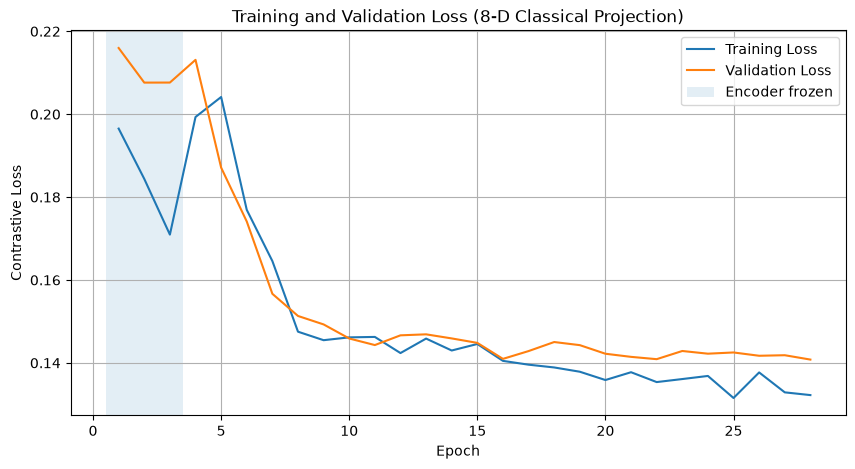

In [22]:
# ============================================================
# CELL 23: Plot training and validation loss
# ============================================================

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs, history["train_loss"], label="Training Loss")

plt.plot(epochs, history["validation_loss"], label="Validation Loss")

if FREEZE_ENCODER_EPOCHS > 0:

    plt.axvspan(
        0.5, min(FREEZE_ENCODER_EPOCHS, len(history["train_loss"])) + 0.5,
        alpha=0.12, label="Encoder frozen"
    )

plt.xlabel("Epoch")

plt.ylabel("Contrastive Loss")

plt.title("Training and Validation Loss (8-D Classical Projection)")

plt.legend()

plt.grid()

plt.show()

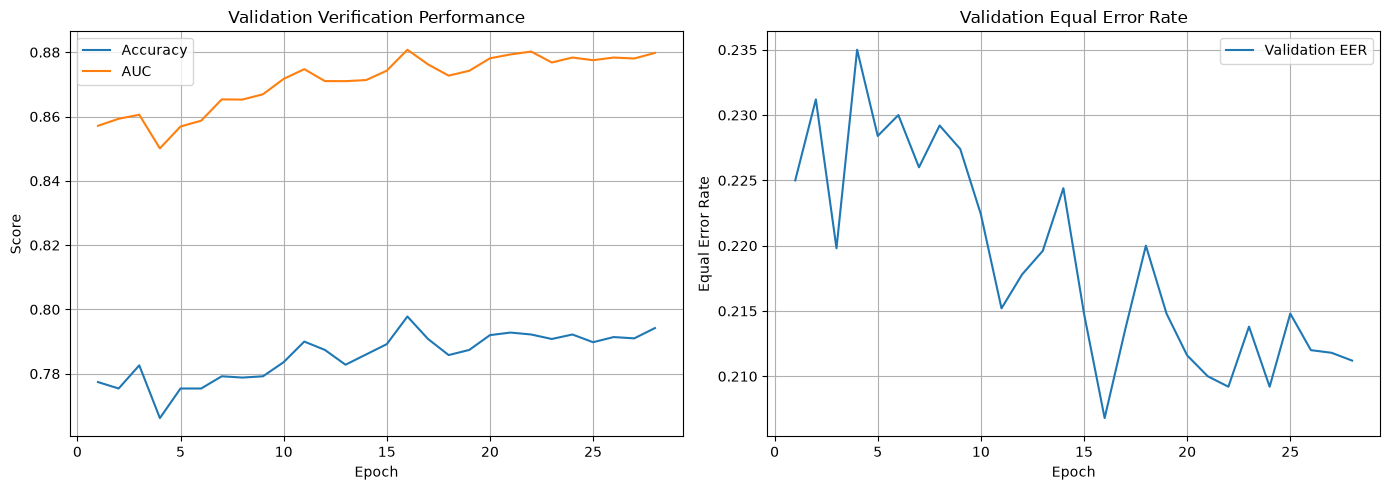

In [23]:
# ============================================================
# CELL 24: Plot validation performance and EER
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history["validation_accuracy"], label="Accuracy")

axes[0].plot(epochs, history["validation_auc"], label="AUC")

axes[0].set_xlabel("Epoch")

axes[0].set_ylabel("Score")

axes[0].set_title("Validation Verification Performance")

axes[0].legend()

axes[0].grid()

axes[1].plot(epochs, history["validation_eer"], label="Validation EER")

axes[1].set_xlabel("Epoch")

axes[1].set_ylabel("Equal Error Rate")

axes[1].set_title("Validation Equal Error Rate")

axes[1].legend()

axes[1].grid()

plt.tight_layout()

plt.show()

In [24]:
# ============================================================
# CELL 25: Load best model
# ============================================================

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

best_threshold = float(checkpoint["threshold"])

best_eer_threshold = float(checkpoint["eer_threshold"])


print("Best classical projection model loaded successfully.")

print("\nBest Epoch:", checkpoint["epoch"])

print("Validation AUC:", checkpoint["validation_auc"])

print("Validation Accuracy:", checkpoint["validation_accuracy"])

print("Validation EER:", checkpoint["validation_eer"])

print("Selected Threshold:", best_threshold)

Best classical projection model loaded successfully.

Best Epoch: 16
Validation AUC: 0.88077344
Validation Accuracy: 0.7978
Validation EER: 0.20679999999999998
Selected Threshold: 0.4526037275791168


In [25]:
# ============================================================
# CELL 26: Final test evaluation (threshold from validation only)
# ============================================================

test_loss, test_distances, test_labels = evaluate_model(
    model, test_loader, criterion
)

test_predictions = predict_from_distance(test_distances, best_threshold)

test_accuracy = accuracy_score(test_labels, test_predictions)

test_metrics = get_validation_metrics(test_distances, test_labels)

test_auc = test_metrics["auc"]

test_fpr = test_metrics["fpr"]

test_tpr = test_metrics["tpr"]

test_far, test_frr = calculate_far_frr(
    test_distances, test_labels, best_threshold
)


print("=" * 65)

print("FINAL IDENTITY-DISJOINT TEST RESULTS (8-D CLASSICAL PROJECTION)")

print("=" * 65)

print(f"\nTest Loss: {test_loss:.4f}")

print(f"Test Accuracy: {test_accuracy:.4f}")

print(f"Test AUC: {test_auc:.4f}")

print(f"Test EER: {test_metrics['eer']:.4f}")

print(f"False Acceptance Rate (FAR): {test_far:.4f}")

print(f"False Rejection Rate (FRR): {test_frr:.4f}")

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

FINAL IDENTITY-DISJOINT TEST RESULTS (8-D CLASSICAL PROJECTION)

Test Loss: 0.1414
Test Accuracy: 0.7858
Test AUC: 0.8747
Test EER: 0.2218
False Acceptance Rate (FAR): 0.2516
False Rejection Rate (FRR): 0.1768


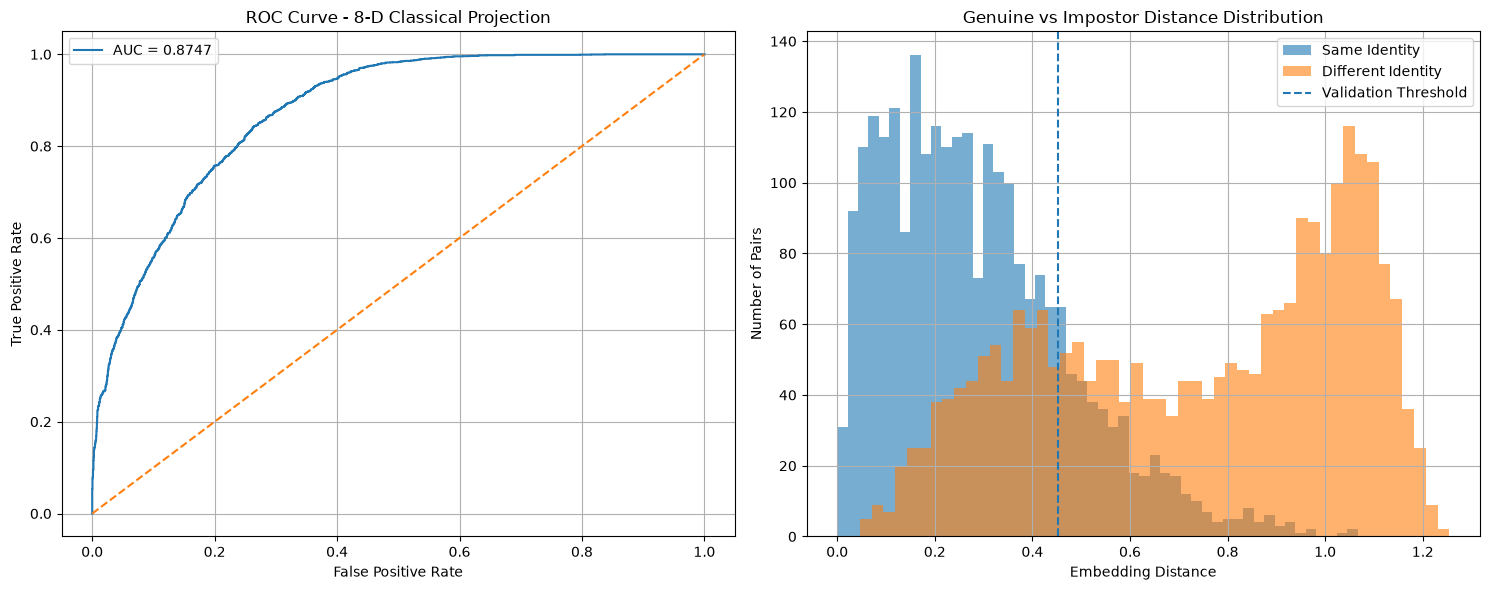

In [26]:
# ============================================================
# CELL 27: ROC curve and distance distributions
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].plot(test_fpr, test_tpr, label=f"AUC = {test_auc:.4f}")

axes[0].plot([0, 1], [0, 1], linestyle="--")

axes[0].set_xlabel("False Positive Rate")

axes[0].set_ylabel("True Positive Rate")

axes[0].set_title("ROC Curve - 8-D Classical Projection")

axes[0].legend()

axes[0].grid()


genuine_distances = test_distances[test_labels == 0]

impostor_distances = test_distances[test_labels == 1]

axes[1].hist(genuine_distances, bins=50, alpha=0.6, label="Same Identity")

axes[1].hist(impostor_distances, bins=50, alpha=0.6,
             label="Different Identity")

axes[1].axvline(best_threshold, linestyle="--", label="Validation Threshold")

axes[1].set_xlabel("Embedding Distance")

axes[1].set_ylabel("Number of Pairs")

axes[1].set_title("Genuine vs Impostor Distance Distribution")

axes[1].legend()

axes[1].grid()

plt.tight_layout()

plt.show()

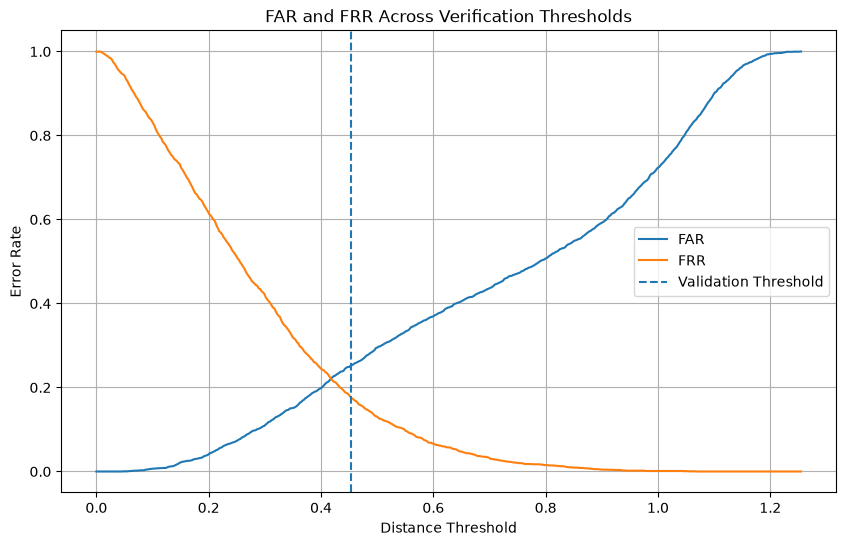

In [27]:
# ============================================================
# CELL 28: FAR and FRR across thresholds
# ============================================================

thresholds = np.linspace(test_distances.min(), test_distances.max(), 500)

far_values, frr_values = [], []

for threshold in thresholds:

    far, frr = calculate_far_frr(test_distances, test_labels, threshold)

    far_values.append(far)

    frr_values.append(frr)


plt.figure(figsize=(10, 6))

plt.plot(thresholds, far_values, label="FAR")

plt.plot(thresholds, frr_values, label="FRR")

plt.axvline(best_threshold, linestyle="--", label="Validation Threshold")

plt.xlabel("Distance Threshold")

plt.ylabel("Error Rate")

plt.title("FAR and FRR Across Verification Thresholds")

plt.legend()

plt.grid()

plt.show()

Comparing:   0%|          | 0/313 [00:00<?, ?it/s]

Comparing:   0%|          | 0/313 [00:00<?, ?it/s]

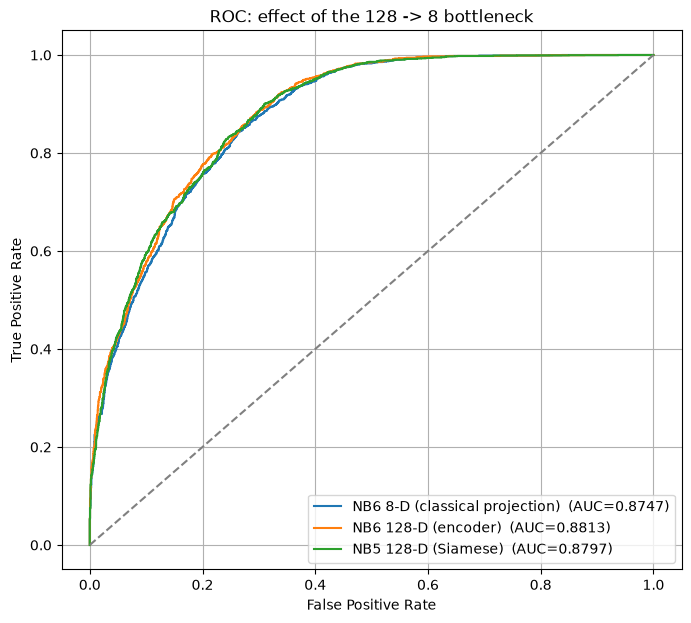

,model,embedding_dim,test_auc,test_eer,auc_change_vs_nb5
0,NB6 8-D (classical projection),8,0.874688,0.2218,-0.004997
1,NB6 128-D (encoder),128,0.881310,0.2108,0.001624
2,NB5 128-D (Siamese),128,0.879686,0.2192,0.000000


In [28]:
# ============================================================
# CELL 29: Compare with Notebook 5 (128-D) on the SAME test pairs
# ============================================================
#
# Quantifies the cost of the 128 -> 8 bottleneck.
#   - "NB5 128-D"        : Notebook 5 encoder, unchanged
#   - "NB6 128-D (enc.)" : the fine-tuned encoder inside this notebook,
#                          before the projection head
#   - "NB6 8-D"          : encoder + classical projection head


def pair_distances(embed_fn, dataloader):

    distances, labels = [], []

    with torch.no_grad():

        for image1, image2, label in tqdm(
            dataloader, desc="Comparing", leave=False
        ):

            e1 = embed_fn(image1.to(DEVICE))

            e2 = embed_fn(image2.to(DEVICE))

            distances.extend(F.pairwise_distance(e1, e2).cpu().numpy())

            labels.extend(label.numpy())

    return np.array(distances), np.array(labels)


model.eval()

curves = {}

# --- NB6 8-D -------------------------------------------------------
curves["NB6 8-D (classical projection)"] = (test_distances, test_labels, PROJECTION_DIM)

# --- NB6 128-D (fine-tuned encoder, before the head) ---------------
d128, l128 = pair_distances(model.encoder, test_loader)

curves["NB6 128-D (encoder)"] = (d128, l128, ENCODER_EMBEDDING_DIM)

# --- NB5 128-D (original) ------------------------------------------
if NB5_MODEL_PATH.exists():

    nb5_encoder = SiameseEncoder(
        embedding_dim=ENCODER_EMBEDDING_DIM,
        pretrained=False
    ).to(DEVICE)

    nb5_ckpt = torch.load(
        NB5_MODEL_PATH, map_location=DEVICE, weights_only=False
    )

    nb5_encoder.load_state_dict(
        {
            k[len("encoder."):]: v
            for k, v in nb5_ckpt["model_state_dict"].items()
            if k.startswith("encoder.")
        }
    )

    nb5_encoder.eval()

    d5, l5 = pair_distances(nb5_encoder, test_loader)

    curves["NB5 128-D (Siamese)"] = (d5, l5, ENCODER_EMBEDDING_DIM)

    del nb5_encoder


rows = []

plt.figure(figsize=(8, 7))

for name, (distances, labels, dim) in curves.items():

    metrics = get_validation_metrics(distances, labels)

    rows.append(
        {
            "model": name,
            "embedding_dim": dim,
            "test_auc": metrics["auc"],
            "test_eer": metrics["eer"],
        }
    )

    plt.plot(
        metrics["fpr"], metrics["tpr"],
        label=f"{name}  (AUC={metrics['auc']:.4f})"
    )


plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC: effect of the 128 -> 8 bottleneck")

plt.legend()

plt.grid()

plt.show()


comparison_df = pd.DataFrame(rows)

if "NB5 128-D (Siamese)" in curves:

    nb5_auc = comparison_df.loc[
        comparison_df["model"] == "NB5 128-D (Siamese)", "test_auc"
    ].iloc[0]

    comparison_df["auc_change_vs_nb5"] = comparison_df["test_auc"] - nb5_auc

comparison_df.to_csv(OUTPUT_DIR / "comparison_vs_notebook5.csv", index=False)

display(comparison_df)

In [29]:
# ============================================================
# CELL 30: Extract and save 8-D (and 128-D) embeddings
# ============================================================
#
# Cached features for Notebooks 7-9 (quantum circuit experiments and
# few-shot evaluation) so the backbone does not have to be re-run.


class ImagePathDataset(Dataset):

    def __init__(self, paths, transform):

        self.paths = list(paths)

        self.transform = transform

    def __len__(self):

        return len(self.paths)

    def __getitem__(self, index):

        image = Image.open(self.paths[index]).convert("RGB")

        return self.transform(image)


@torch.no_grad()
def extract_embeddings(dataframe):

    loader = DataLoader(
        ImagePathDataset(dataframe[PATH_COLUMN], evaluation_transform),
        batch_size=64,
        shuffle=False,
        num_workers=NUM_WORKERS
    )

    model.eval()

    all_128, all_8 = [], []

    for batch in tqdm(loader, desc="Embedding", leave=False):

        e128, e8 = model.embed_both(batch.to(DEVICE))

        all_128.append(e128.cpu().numpy())

        all_8.append(e8.cpu().numpy())

    return np.concatenate(all_128), np.concatenate(all_8)


for split_name, dataframe in [
    ("train", train_df),
    ("validation", validation_df),
    ("test", test_df),
]:

    e128, e8 = extract_embeddings(dataframe)

    np.savez_compressed(
        OUTPUT_DIR / f"{split_name}_embeddings.npz",
        embeddings_128=e128,
        embeddings_8=e8,
        identities=dataframe[IDENTITY_COLUMN].values,
        paths=dataframe[PATH_COLUMN].values
    )

    print(f"{split_name:10s} 128-D {e128.shape}  8-D {e8.shape}")


print("\nEmbeddings saved to:", OUTPUT_DIR)

Embedding:   0%|          | 0/219 [00:00<?, ?it/s]

train      128-D (14000, 128)  8-D (14000, 8)


Embedding:   0%|          | 0/47 [00:00<?, ?it/s]

validation 128-D (3000, 128)  8-D (3000, 8)


Embedding:   0%|          | 0/47 [00:00<?, ?it/s]

test       128-D (3000, 128)  8-D (3000, 8)

Embeddings saved to: ..\classical_projection_baseline


In [30]:
# ============================================================
# CELL 31: Save training history, results and configuration
# ============================================================

pd.DataFrame(history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)


results = {
    "best_epoch": checkpoint["epoch"],
    "best_validation_loss": checkpoint["validation_loss"],
    "best_validation_accuracy": checkpoint["validation_accuracy"],
    "best_validation_auc": checkpoint["validation_auc"],
    "best_validation_eer": checkpoint["validation_eer"],
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "test_auc": test_auc,
    "test_eer": test_metrics["eer"],
    "test_far": test_far,
    "test_frr": test_frr,
    "validation_threshold": best_threshold,
    "validation_eer_threshold": best_eer_threshold,
    "embedding_dimension": PROJECTION_DIM,
    "same_eval_pairs_as_nb5": SAME_PAIRS_AS_NB5
}

results_df = pd.DataFrame([results])

results_df.to_csv(OUTPUT_DIR / "final_results.csv", index=False)

display(results_df)


configuration = {
    "seed": SEED,
    "backbone": BACKBONE,
    "warm_start_from_nb5": WARM_START_FROM_NB5,
    "image_size": IMAGE_SIZE,
    "batch_size_pairs": BATCH_SIZE,
    "epochs_requested": NUM_EPOCHS,
    "freeze_encoder_epochs": FREEZE_ENCODER_EPOCHS,
    "encoder_lr": ENCODER_LR,
    "head_lr": HEAD_LR,
    "weight_decay": WEIGHT_DECAY,
    "encoder_embedding_dimension": ENCODER_EMBEDDING_DIM,
    "projection_dimension": PROJECTION_DIM,
    "projection_hidden": PROJECTION_HIDDEN,
    "projection_dropout": PROJECTION_DROPOUT,
    "contrastive_margin": CONTRASTIVE_MARGIN,
    "training_pairs_per_epoch": TRAIN_PAIRS_PER_EPOCH,
    "validation_pairs": VALIDATION_PAIRS,
    "test_pairs": TEST_PAIRS
}

pd.DataFrame([configuration]).to_csv(
    OUTPUT_DIR / "experiment_configuration.csv", index=False
)

print("\nTraining history, results and configuration saved.")

,best_epoch,best_validation_loss,best_validation_accuracy,best_validation_auc,best_validation_eer,test_loss,test_accuracy,test_auc,test_eer,test_far,test_frr,validation_threshold,validation_eer_threshold,embedding_dimension,same_eval_pairs_as_nb5
0,16,0.140965,0.7978,0.880773,0.2068,0.141401,0.7858,0.874688,0.2218,0.2516,0.1768,0.452604,0.42039,8,True



Training history, results and configuration saved.


In [31]:
# ============================================================
# CELL 32: Final Summary
# ============================================================

print("=" * 70)

print("NOTEBOOK 6 COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nCLASSICAL 128 -> 8 PROJECTION BASELINE")

print(f"\nProjection Dimension: {PROJECTION_DIM}")

print(f"Best Epoch: {checkpoint['epoch']}")

print(f"Best Validation AUC: {checkpoint['validation_auc']:.4f}")

print(f"Best Validation EER: {checkpoint['validation_eer']:.4f}")

print(f"\nFinal Test Accuracy: {test_accuracy:.4f}")

print(f"Final Test AUC: {test_auc:.4f}")

print(f"Final Test EER: {test_metrics['eer']:.4f}")

print(f"Final Test FAR: {test_far:.4f}")

print(f"Final Test FRR: {test_frr:.4f}")

print(f"\nValidation-selected Threshold: {best_threshold:.4f}")

print("\nComparison with Notebook 5:")

display(comparison_df)

print("\nSaved Model:")

print(BEST_MODEL_PATH)

print("\nOutput Directory:")

print(OUTPUT_DIR)

print("\n✓ Notebook 6 is complete.")

NOTEBOOK 6 COMPLETED SUCCESSFULLY

CLASSICAL 128 -> 8 PROJECTION BASELINE

Projection Dimension: 8
Best Epoch: 16
Best Validation AUC: 0.8808
Best Validation EER: 0.2068

Final Test Accuracy: 0.7858
Final Test AUC: 0.8747
Final Test EER: 0.2218
Final Test FAR: 0.2516
Final Test FRR: 0.1768

Validation-selected Threshold: 0.4526

Comparison with Notebook 5:


,model,embedding_dim,test_auc,test_eer,auc_change_vs_nb5
0,NB6 8-D (classical projection),8,0.874688,0.2218,-0.004997
1,NB6 128-D (encoder),128,0.881310,0.2108,0.001624
2,NB5 128-D (Siamese),128,0.879686,0.2192,0.000000



Saved Model:
..\classical_projection_baseline\best_classical_projection_model.pth

Output Directory:
..\classical_projection_baseline

✓ Notebook 6 is complete.


## Notes for Notebook 7 (quantum circuit experiments)

- The 8-D embedding is L2-normalised, so every coordinate lies in [-1, 1].
  For angle encoding multiply by π (or use `arcsin`/`arccos`) so each
  coordinate becomes a rotation angle in [-π, π].
- `train/validation/test_embeddings.npz` contain cached 128-D and 8-D
  embeddings. They are produced by the *fine-tuned* encoder of this
  notebook, so the quantum model must be compared against
  `final_results.csv` from this notebook and evaluated on the same
  `validation_pairs.csv` / `test_pairs.csv`.
- `model_config.json` holds everything needed to rebuild the encoder.